## Data

This project uses Earnings-21, a set of 44 English earnings calls with human reference transcripts, loaded from the Hugging Face ASR leaderboard long-form collection. Earnings calls are a realistic captioning use case since they mix multiple speakers, numbers, company names and financial terms.

The analysis uses the first two of the ten data files, which hold 10 calls and about 10.75 hours of audio across six sectors. TED-LIUM was the original choice, but it is no longer available through Hugging Face.

In [24]:
from huggingface_hub import hf_hub_download
from datasets import load_dataset

# load the two earnings-21 files that already finished downloading
repo = "hf-audio/asr-leaderboard-longform"
names = ["earnings21/test-00000-of-00010.parquet", "earnings21/test-00001-of-00010.parquet"]
paths = [hf_hub_download(repo, n, repo_type="dataset") for n in names]

ds = load_dataset("parquet", data_files=paths, split="train")

print(ds)
print()

for s in ds.remove_columns("audio"):
    print(s["company_name"], s["sector"], s["unique_speakers"], round(s["audio_length"] / 60), "min")

Dataset({
    features: ['audio', 'audio_length', 'original_sample_rate', 'company_name', 'financial_quarter', 'sector', 'speaker_switches', 'unique_speakers', 'curator_id', 'text'],
    num_rows: 10
})

Monro Inc Consumer Goods 10 55 min
Culp Inc Industrial Goods 8 41 min
General Electric Conglomerate 14 96 min
Danaher Corp Conglomerate 7 45 min
Spire Inc Utilities 10 55 min
Ingersoll Rand Industrial Goods 14 66 min
Cementos Argos Industrial Goods 20 78 min
Kuehne Nagel International Services 13 81 min
Constellium Industrial Goods 10 63 min
Travelers Companies Inc Financial 15 65 min


## Transcription test

Before transcribing all 10 calls, this cell runs Whisper on the first two minutes of the Culp Inc call, which is the shortest in the subset. It checks how long transcription takes on a Mac and gives a first look at how Whisper’s output compares with the human reference.

In [25]:
import time
import whisper
from datasets import Audio

# get the culp call as raw audio bytes so whisper can decode it with ffmpeg
ds_raw = ds.cast_column("audio", Audio(decode=False))
idx = list(ds["company_name"]).index("Culp Inc")
culp = ds_raw[idx]

with open("culp.wav", "wb") as f:
    f.write(culp["audio"]["bytes"])

# load the audio at 16 kHz and keep the first two minutes
audio = whisper.load_audio("culp.wav")
clip = audio[: 16000 * 120]

model = whisper.load_model("small.en")

start = time.time()
result = model.transcribe(clip, fp16=False)
elapsed = time.time() - start

print(round(elapsed), "seconds to transcribe 2 minutes of audio")
print(round(elapsed / 2 * 645 / 60, 1), "estimated hours for all 10 calls")
print()
print(result["text"])
print()
print(culp["text"][:1500])

17 seconds to transcribe 2 minutes of audio
88.8 estimated hours for all 10 calls

 Good day and welcome to Culp's third quarter 2020 earnings conference call. Today's call is being recorded at this time for opening remarks and introductions. I'd like to turn the call over to Ms. Drew Anderson. Please go ahead. Thank you. Good morning and welcome to the Culp conference call to review the company's results for the third quarter of fiscal 2020. As we start, let me state that this morning's call will contain forward-looking statements about the business, financial condition, and prospects of the company. Forward-looking statements are statements that include projections, expectations, or beliefs about future events or results, or otherwise are not statements of historical fact. The actual performance of the company could differ materially from that indicated by the forward-looking statements because of various risks and uncertainties. These risks and uncertainties are described in our reg

## Transcribing all calls

The test showed that the small.en model transcribes about 8 times faster than real time, so all 10 calls take roughly 78 minutes. That makes small.en a good balance of speed and accuracy for this project.

Each finished call is saved to whisper_transcripts.csv along with its reference transcript and metadata. If the run is interrupted, rerunning the cell skips calls that are already saved.

In [26]:
import os
import pandas as pd

# load any transcripts saved from an earlier run so finished calls are skipped
rows = []
if os.path.exists("whisper_transcripts.csv"):
    rows = pd.read_csv("whisper_transcripts.csv").to_dict("records")
done = {r["company_name"] for r in rows}

for i in range(len(ds_raw)):
    call = ds_raw[i]
    name = call["company_name"]
    if name in done:
        continue

    with open("call.wav", "wb") as f:
        f.write(call["audio"]["bytes"])
    audio = whisper.load_audio("call.wav")

    start = time.time()
    result = model.transcribe(audio, fp16=False)
    minutes = round((time.time() - start) / 60, 1)

    rows.append({
        "company_name": name,
        "sector": call["sector"],
        "unique_speakers": call["unique_speakers"],
        "speaker_switches": call["speaker_switches"],
        "audio_minutes": round(call["audio_length"] / 60, 1),
        "transcribe_minutes": minutes,
        "whisper_text": result["text"],
        "reference_text": call["text"],
    })

    # save after every call so progress is never lost
    pd.DataFrame(rows).to_csv("whisper_transcripts.csv", index=False)
    print(name, "done in", minutes, "minutes")

## Word error rate

Word error rate (WER) counts the substituted, deleted and inserted words needed to turn Whisper's transcript into the reference, divided by the number of reference words. Both transcripts are normalized first so that case and punctuation are not counted as errors.

WER is computed two ways. **Light normalization** only lowercases and removes punctuation. **Full normalization** uses Whisper's English normalizer, which also standardizes numbers, spellings and contractions and removes filler words like "um" and "uh." Full normalization is the standard used by the Open ASR Leaderboard, so these results can be compared with published numbers.

Overall WER is 14.8% with light normalization and 11.8% with full normalization. The gap shows that about a fifth of the apparent errors come from formatting differences and not recognition mistakes. Removing filler words also means these results treat clean verbatim captions as the standard.

In [27]:
import re
import jiwer
from whisper.normalizers import EnglishTextNormalizer

df = pd.read_csv("whisper_transcripts.csv")
normalizer = EnglishTextNormalizer()

# light normalization lowercases and removes punctuation but keeps word forms
def light_normalize(text):
    text = text.lower()
    text = re.sub(r"[^\w\s']", " ", text)
    return " ".join(text.split())

df["ref_light"] = df["reference_text"].apply(light_normalize)
df["hyp_light"] = df["whisper_text"].apply(light_normalize)
df["ref_full"] = df["reference_text"].apply(normalizer)
df["hyp_full"] = df["whisper_text"].apply(normalizer)

df["wer_light"] = [jiwer.wer(r, h) for r, h in zip(df["ref_light"], df["hyp_light"])]
df["wer_full"] = [jiwer.wer(r, h) for r, h in zip(df["ref_full"], df["hyp_full"])]

print(df[["company_name", "sector", "unique_speakers", "wer_light", "wer_full"]].round(3))
print()
print("overall light WER", round(jiwer.wer(list(df["ref_light"]), list(df["hyp_light"])), 3))
print("overall full WER", round(jiwer.wer(list(df["ref_full"]), list(df["hyp_full"])), 3))

                 company_name            sector  unique_speakers  wer_light  \
0                   Monro Inc    Consumer Goods               10      0.109   
1                    Culp Inc  Industrial Goods                8      0.095   
2            General Electric      Conglomerate               14      0.144   
3                Danaher Corp      Conglomerate                7      0.135   
4                   Spire Inc         Utilities               10      0.104   
5              Ingersoll Rand  Industrial Goods               14      0.195   
6              Cementos Argos  Industrial Goods               20      0.268   
7  Kuehne Nagel International          Services               13      0.164   
8                 Constellium  Industrial Goods               10      0.119   
9     Travelers Companies Inc         Financial               15      0.106   

   wer_full  
0     0.085  
1     0.080  
2     0.122  
3     0.094  
4     0.081  
5     0.170  
6     0.239  
7     0.101  
8   

## Types of errors

WER combines three kinds of errors. **Substitutions** are wrong words, **deletions** are missed words and **insertions** are added words. This cell counts each type per call and lists the most common substituted word pairs across all calls.

The substitutions fall into four groups.

- **Formatting differences**, such as "cashflow" in the reference and "cash flow" in Whisper's output
- **Reference errors where Whisper is correct**, such as "Columbia" for the Colombian company Cementos Argos
- **Proper noun errors**, where Whisper uses a more common spelling of an unfamiliar name, such as "Monroe" for Monro and "Paul" for Pall
- **Short unstressed words and grammatical forms**, such as "and" and "in" or "were" and "are"

In [28]:
from collections import Counter

# split each call's errors into substitutions deletions and insertions
# and collect every substituted word pair across all calls
counts = []
swaps = Counter()

for _, row in df.iterrows():
    out = jiwer.process_words(row["ref_full"], row["hyp_full"])
    ref, hyp = out.references[0], out.hypotheses[0]

    counts.append({
        "company_name": row["company_name"],
        "ref_words": len(ref),
        "substitutions": out.substitutions,
        "deletions": out.deletions,
        "insertions": out.insertions,
    })

    for chunk in out.alignments[0]:
        if chunk.type == "substitute":
            ref_span = ref[chunk.ref_start_idx:chunk.ref_end_idx]
            hyp_span = hyp[chunk.hyp_start_idx:chunk.hyp_end_idx]
            for r, h in zip(ref_span, hyp_span):
                swaps[(r, h)] += 1

err = pd.DataFrame(counts)
print(err.to_string(index=False))
print()

for (r, h), n in swaps.most_common(30):
    print(n, r, "->", h)

              company_name  ref_words  substitutions  deletions  insertions
                 Monro Inc       8675            313        340          81
                  Culp Inc       6639            239        209          86
          General Electric      14643            532       1018         239
              Danaher Corp       6946            225        371          58
                 Spire Inc       9133            236        412          90
            Ingersoll Rand      10996            673       1044         148
            Cementos Argos      10157           1177        860         388
Kuehne Nagel International      11576            440        601         130
               Constellium       9604            290        455          83
   Travelers Companies Inc      10499            319        514          98

38 and -> in
37 in -> and
26 monro -> monroe
24 the -> a
24 a -> the
22 these -> this
19 costs -> cost
15 cashflow -> flow
15 202 -> 2020
15 columbia -> colombia
1

## Checking errors in context

This function prints the words around each instance of a substitution in both transcripts, which makes it possible to tell real recognition errors apart from formatting or reference problems.

In [29]:
# show the surrounding words for each instance of a reference to whisper swap
def show_swap(ref_word, hyp_word, window=6, limit=5):
    shown = 0
    for _, row in df.iterrows():
        out = jiwer.process_words(row["ref_full"], row["hyp_full"])
        ref, hyp = out.references[0], out.hypotheses[0]
        for chunk in out.alignments[0]:
            if chunk.type != "substitute":
                continue
            for k in range(chunk.ref_end_idx - chunk.ref_start_idx):
                ri = chunk.ref_start_idx + k
                hi = chunk.hyp_start_idx + k
                if ref[ri] == ref_word and hyp[hi] == hyp_word:
                    print(row["company_name"])
                    print("ref ", " ".join(ref[max(0, ri - window):ri + window]))
                    print("hyp ", " ".join(hyp[max(0, hi - window):hi + window]))
                    print()
                    shown += 1
                    if shown >= limit:
                        return

show_swap("202", "2020")
show_swap("cashflow", "flow")
show_swap("and", "in")

Spire Inc
ref  the 2nd half of our fiscal 202 turning to our results for
hyp  the 2nd half of our fiscal 2020 turning to our results for

Spire Inc
ref  equity needs for the remainder of 202 so in summary we are
hyp  equity needs for the remainder of 2020 so in summary we are

Kuehne Nagel International
ref  419000000 in the 1st half of 202 earnings per share landed at
hyp  francs in the 1st half of 2020 earnings per share landed at

Kuehne Nagel International
ref  more than tripled in quarter 2 202 road logistics ended the 1st
hyp  more than tripled in quarter to 2020 road logistics ended the 1st

Kuehne Nagel International
ref  the end of the 1st quarter 202 so simple terms a very
hyp  the end of the 1st quarter 2020 simple terms a very good

Culp Inc
ref  respect to certain forward looking free cashflow information the comparable gaap and
hyp  to certain forward looking free cash flow information the comparable gaap and

Culp Inc
ref  the significance of the historical free cashflow

## Investigating the year errors

The normalized reference contained "202" in several places where Whisper wrote "2020." These cells check how years are written in the raw reference text and then look at the raw text at two of those spots.

The raw reference itself says "202," so these are typos made by the original transcriber and not a normalizer problem. The "201" errors follow the same pattern. In these cases WER counted Whisper as wrong even though it heard the year correctly.

In [30]:
from collections import Counter

# collect every token in the raw references that contains a year
year_forms = Counter()
for text in df["reference_text"]:
    year_forms.update(re.findall(r"\S*20[12]\d\S*", text))

for form, n in year_forms.most_common(30):
    print(n, repr(form))

63 '2020'
25 '2020,'
17 '2020.'
14 '2019.'
12 '2019,'
12 '2019'
9 '2021,'
9 '2021'
3 '2021.'
3 '2015'
2 '2016'
2 '2018.'
2 '2019?'
2 '2018'
2 '2022,'
1 '2017'
1 '2022'
1 '2023.'
1 "2020's,"
1 '2016,'
1 '2024'
1 '2018,'
1 '2027.'
1 '2020?'
1 '2028,'
1 '2025'
1 '2013'


In [31]:
# pull the raw reference text where the 202 problem appeared and normalize it
spire = df.loc[df["company_name"] == "Spire Inc", "reference_text"].iloc[0]
kuehne = df.loc[df["company_name"] == "Kuehne Nagel International", "reference_text"].iloc[0]

for text, phrase in [(spire, "remainder of"), (kuehne, "end of the first quarter")]:
    i = text.find(phrase)
    snippet = text[i:i + 70]
    print(repr(snippet))
    print(normalizer(snippet))
    print()

"remainder of 202. So in summary, we're in solid shape and remain focus"
remainder of 202 so in summary we are in solid shape and remain focus

'end of the first quarter 202. So, um, simple terms, a very good, uh, u'
end of the 1st quarter 202 so simple terms a very good u



## Cleaning up conventions and reference errors

This step applies two small sets of fixes and recomputes WER.

- **Convention fixes** are applied to both transcripts so that spacing choices like "cashflow" and "cash flow" match.
- **Reference fixes** are applied only to the reference and correct typos confirmed in the raw text. "Columbia" is corrected only in the Cementos Argos call, where it refers to the country.

The cleanup lowers overall WER only slightly, from 11.8% to 11.6%. Reference typos and spacing conventions are real but minor, and nearly all of the remaining error is genuine recognition error. Cementos Argos still has the highest WER at 23.6%, so its high error rate needs another explanation.

In [32]:
# spacing conventions that differ between transcripts and are not real errors
convention_fixes = {"cashflow": "cash flow", "healthcare": "health care", "longterm": "long term", "u s": "us"}

# typos in the reference transcripts confirmed by checking the raw text
reference_fixes = {"202": "2020", "201": "2019"}

def apply_fixes(text, fixes):
    for old, new in fixes.items():
        text = re.sub(rf"\b{re.escape(old)}\b", new, text)
    return text

df["ref_clean"] = df["ref_full"].apply(apply_fixes, fixes=convention_fixes).apply(apply_fixes, fixes=reference_fixes)
df["hyp_clean"] = df["hyp_full"].apply(apply_fixes, fixes=convention_fixes)

# colombia is only fixed in the cementos argos call where it refers to the country
is_argos = df["company_name"] == "Cementos Argos"
df.loc[is_argos, "ref_clean"] = df.loc[is_argos, "ref_clean"].str.replace(r"\bcolumbia\b", "colombia", regex=True)

df["wer_clean"] = [jiwer.wer(r, h) for r, h in zip(df["ref_clean"], df["hyp_clean"])]

print(df[["company_name", "wer_light", "wer_full", "wer_clean"]].round(3).to_string(index=False))
print()
print("overall light WER", round(jiwer.wer(list(df["ref_light"]), list(df["hyp_light"])), 3))
print("overall full WER", round(jiwer.wer(list(df["ref_full"]), list(df["hyp_full"])), 3))
print("overall clean WER", round(jiwer.wer(list(df["ref_clean"]), list(df["hyp_clean"])), 3))

              company_name  wer_light  wer_full  wer_clean
                 Monro Inc      0.109     0.085      0.084
                  Culp Inc      0.095     0.080      0.078
          General Electric      0.144     0.122      0.120
              Danaher Corp      0.135     0.094      0.094
                 Spire Inc      0.104     0.081      0.079
            Ingersoll Rand      0.195     0.170      0.169
            Cementos Argos      0.268     0.239      0.236
Kuehne Nagel International      0.164     0.101      0.100
               Constellium      0.119     0.086      0.083
   Travelers Companies Inc      0.106     0.089      0.087

overall light WER 0.148
overall full WER 0.118
overall clean WER 0.116


## Deletions and insertions

WER treats every missing or added word the same way, so this cell splits each call's errors into **substitution**, **deletion** and **insertion** rates. It also lists the longest runs of deleted or inserted words, since a long run can point to a stretch of audio Whisper skipped or a phrase it repeated.

Deletions are the most common error type in most calls. Cementos Argos and Ingersoll Rand stand out for different reasons. Cementos Argos has a substitution rate three times higher than the other calls, which means Whisper heard the speech but got many words wrong. Ingersoll Rand has a normal substitution rate but the highest deletion rate and the three longest deleted runs.

In [33]:
# error rates by type for each call using the cleaned transcripts
# and every run of deleted or inserted words
rate_rows = []
runs = []

for _, row in df.iterrows():
    out = jiwer.process_words(row["ref_clean"], row["hyp_clean"])
    ref, hyp = out.references[0], out.hypotheses[0]
    n = len(ref)

    rate_rows.append({
        "company_name": row["company_name"],
        "sub_rate": out.substitutions / n,
        "del_rate": out.deletions / n,
        "ins_rate": out.insertions / n,
    })

    for chunk in out.alignments[0]:
        if chunk.type == "delete":
            words = ref[chunk.ref_start_idx:chunk.ref_end_idx]
            runs.append((len(words), "deleted", row["company_name"], " ".join(words)))
        elif chunk.type == "insert":
            words = hyp[chunk.hyp_start_idx:chunk.hyp_end_idx]
            runs.append((len(words), "inserted", row["company_name"], " ".join(words)))

rates = pd.DataFrame(rate_rows)
print(rates.round(3).to_string(index=False))
print()

# the longest stretches of missed or added words
for length, kind, name, words in sorted(runs, reverse=True)[:15]:
    print(length, "words", kind, "in", name)
    print(words[:300])
    print()

              company_name  sub_rate  del_rate  ins_rate
                 Monro Inc     0.036     0.039     0.009
                  Culp Inc     0.034     0.032     0.012
          General Electric     0.035     0.069     0.015
              Danaher Corp     0.032     0.053     0.008
                 Spire Inc     0.025     0.045     0.009
            Ingersoll Rand     0.061     0.095     0.013
            Cementos Argos     0.114     0.084     0.038
Kuehne Nagel International     0.037     0.052     0.011
               Constellium     0.028     0.047     0.008
   Travelers Companies Inc     0.030     0.049     0.009

109 words deleted in Ingersoll Rand
bolt on in pst it is obviously pretty fragment market you probably have a sheriffs call it 16% in in that space how do you how do you think about this how does that segment look like in a few years i mean it is it is you know from an after market to stick this i know it is a design win and replaceme

76 words deleted in Ingersoll Rand

## Listening to the audio

Whisper's timestamps were not saved, so this function estimates where a phrase falls in a call from its position in the reference transcript and plays 90 seconds of audio around it. The estimate can be off by up to a minute since speaking pace varies across a call.

In [34]:
from IPython.display import Audio

# estimate where a phrase falls in a call from its position in the reference and play that part
def play_near(company, phrase, seconds=90):
    row = df[df["company_name"] == company].iloc[0]
    words = row["ref_clean"].split()
    target = phrase.split()
    pos = next(i for i in range(len(words)) if words[i:i + len(target)] == target)

    center = pos / len(words) * row["audio_minutes"] * 60
    start_sec = max(0, center - seconds / 2)

    idx = list(ds["company_name"]).index(company)
    with open("call.wav", "wb") as f:
        f.write(ds_raw[idx]["audio"]["bytes"])
    audio = whisper.load_audio("call.wav")

    print(company, "starting around minute", round(start_sec / 60, 1))
    clip = audio[int(start_sec * 16000):int((start_sec + seconds) * 16000)]
    return Audio(clip, rate=16000)

play_near("Ingersoll Rand", "bolt on in pst")

Ingersoll Rand starting around minute 60.0


In [35]:
play_near("Cementos Argos", "the")

Cementos Argos starting around minute 0.0


## Comparing a window of audio with both transcripts

This function plots the volume of a 90 second window, transcribes it with Whisper and prints the matching stretch of the reference transcript.

In the Ingersoll Rand window, both speakers are at about the same volume and the low sections are pauses between phrases, so a quiet speaker does not explain the dropped words. The second speaker stutters often. The pauses also drop to complete digital silence, which suggests the call platform cut the audio between phrases.

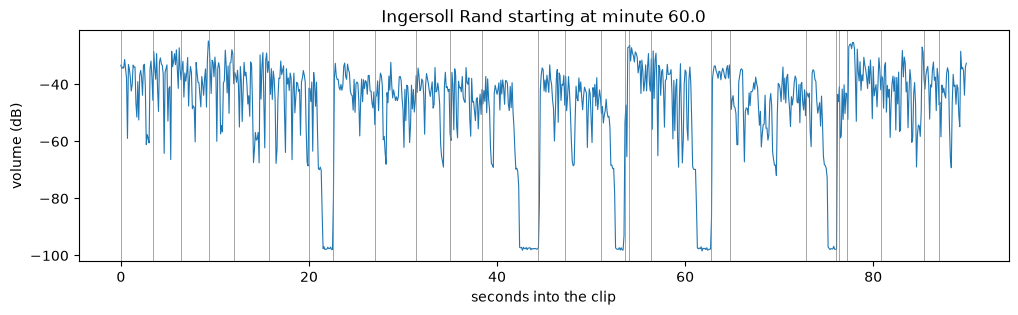

Whisper

0 to 3 s  million savings realized in 2020.
3 to 6 s  What do you currently assume as sort of full run rate savings
6 to 9 s  house that weighs one of the spend, which I think is a third
9 to 12 s  of your overall spend, and how should we think about more
12 to 16 s  medium terms for the other two thirds if you assume that at
16 to 20 s  some point in a normalized third year back to about 2019 levels?
20 to 23 s  Let's start here.
23 to 27 s  Yeah, I think if you think about it, 10 to 20 coming in in
27 to 31 s  this year, as you go into 2021, assuming maybe kind of current
31 to 35 s  volume levels, it will be 20 to 40 million.
35 to 38 s  So that's maybe at least that what you can see here coming
38 to 44 s  from wave one on an analyzed level at current volumes.
44 to 47 s  And that always is only covering a portion of the total
47 to 51 s  spend with a weight two and weight three coming up here in
51 to 54 s  the second half of the year.
54 to 54 s  Right.
54 to 56 s  And i

In [36]:
import matplotlib.pyplot as plt

# plot the volume of a window, transcribe it with timestamps and print the matching reference text
def inspect_window(company, phrase, seconds=90):
    row = df[df["company_name"] == company].iloc[0]
    words = row["ref_clean"].split()
    target = phrase.split()
    pos = next(i for i in range(len(words)) if words[i:i + len(target)] == target)

    center = pos / len(words) * row["audio_minutes"] * 60
    start_sec = max(0, center - seconds / 2)

    idx = list(ds["company_name"]).index(company)
    with open("call.wav", "wb") as f:
        f.write(ds_raw[idx]["audio"]["bytes"])
    audio = whisper.load_audio("call.wav")
    clip = audio[int(start_sec * 16000):int((start_sec + seconds) * 16000)]

    # volume in decibels for every tenth of a second
    frames = clip[:len(clip) // 1600 * 1600].reshape(-1, 1600)
    volume = 20 * np.log10(np.sqrt((frames ** 2).mean(axis=1)) + 1e-9)
    times = np.arange(len(volume)) / 10

    result = model.transcribe(clip, fp16=False)

    plt.figure(figsize=(12, 3))
    plt.plot(times, volume, linewidth=0.8)
    for seg in result["segments"]:
        plt.axvline(seg["start"], color="gray", linewidth=0.5)
    plt.xlabel("seconds into the clip")
    plt.ylabel("volume (dB)")
    plt.title(company + " starting at minute " + str(round(start_sec / 60, 1)))
    plt.show()

    print("Whisper")
    print()
    for seg in result["segments"]:
        print(round(seg["start"]), "to", round(seg["end"]), "s", seg["text"])
    print()

    # the reference window is wider since the position estimate can be off
    words_per_sec = len(words) / (row["audio_minutes"] * 60)
    first = max(0, int((start_sec - 30) * words_per_sec))
    last = int((start_sec + seconds + 30) * words_per_sec)
    print("Reference")
    print()
    print(" ".join(words[first:last]))

inspect_window("Ingersoll Rand", "bolt on in pst")

## Disfluency

The reference transcripts keep repetitions like "the the" and "we are we are," while Whisper usually leaves them out. This cell counts repeated words and phrases per 1,000 words in both transcripts.

Whisper removes about 90 to 99 percent of the repetitions found in the reference. Calls with more repetitions also have higher deletion rates, with a correlation of 0.83 across the 10 calls. With only 10 calls this is a pattern to check and not proof.

In [37]:
# count immediate repetitions like "the the" or "we are we are" in a transcript
def count_repeats(text):
    words = text.split()
    repeats = 0
    for n in (1, 2, 3):
        for i in range(len(words) - 2 * n + 1):
            if words[i:i + n] == words[i + n:i + 2 * n]:
                repeats += n
    return repeats

disfluency = pd.DataFrame({
    "company_name": df["company_name"],
    "ref_repeats_per_1000": [count_repeats(t) / len(t.split()) * 1000 for t in df["ref_clean"]],
    "hyp_repeats_per_1000": [count_repeats(t) / len(t.split()) * 1000 for t in df["hyp_clean"]],
})
disfluency = disfluency.merge(rates[["company_name", "del_rate"]], on="company_name")

print(disfluency.sort_values("ref_repeats_per_1000").round(3).to_string(index=False))
print()
print("correlation between reference repeats and deletion rate", round(disfluency["ref_repeats_per_1000"].corr(disfluency["del_rate"]), 2))

              company_name  ref_repeats_per_1000  hyp_repeats_per_1000  del_rate
                  Culp Inc                11.742                 0.154     0.032
                 Monro Inc                11.987                 0.951     0.039
                 Spire Inc                19.147                 0.681     0.045
   Travelers Companies Inc                22.944                 1.388     0.049
               Constellium                23.115                 2.601     0.047
Kuehne Nagel International                28.932                 3.332     0.052
            Cementos Argos                32.455                 2.997     0.084
          General Electric                32.961                 1.440     0.069
              Danaher Corp                34.101                 1.356     0.053
            Ingersoll Rand                36.283                 3.267     0.095

correlation between reference repeats and deletion rate 0.83


## How many deletions come from repetitions

This cell marks every reference word that is a repeated copy and counts how many of Whisper's deletions fall on those words. Dropped repetitions make up between 26 and 54 percent of deletions depending on the call. These are style differences more than recognition errors, since the reference follows a **true verbatim** standard and Whisper behaves more like a **clean verbatim** captioner.

Repetitions do not explain why Ingersoll Rand and Cementos Argos stand out, though. After removing dropped repetitions, their deletion rates are still 6.8 and 6.2 percent, and the other calls range from 2.0 to 4.1 percent. Their dropped repetition rates are similar to the rest, so the 0.83 correlation partly reflects other differences between calls.

The count is a slight underestimate since it only catches exact repeats and misses false starts like "we were we are."

In [38]:
# mark reference words that are the repeated copy in a repetition like "the the"
def repeat_positions(words):
    marked = set()
    for n in (1, 2, 3):
        for i in range(len(words) - 2 * n + 1):
            if words[i:i + n] == words[i + n:i + 2 * n]:
                marked.update(range(i + n, i + 2 * n))
    return marked

split_rows = []
for _, row in df.iterrows():
    out = jiwer.process_words(row["ref_clean"], row["hyp_clean"])
    ref = out.references[0]
    marked = repeat_positions(ref)

    deleted = [i for chunk in out.alignments[0] if chunk.type == "delete" for i in range(chunk.ref_start_idx, chunk.ref_end_idx)]
    repeat_dels = sum(1 for i in deleted if i in marked)

    split_rows.append({
        "company_name": row["company_name"],
        "del_rate": len(deleted) / len(ref),
        "repeat_del_rate": repeat_dels / len(ref),
        "other_del_rate": (len(deleted) - repeat_dels) / len(ref),
        "pct_dels_from_repeats": repeat_dels / len(deleted) * 100,
    })

split = pd.DataFrame(split_rows)
print(split.sort_values("del_rate").round(3).to_string(index=False))

              company_name  del_rate  repeat_del_rate  other_del_rate  pct_dels_from_repeats
                  Culp Inc     0.032            0.011           0.020                 35.238
                 Monro Inc     0.039            0.011           0.028                 28.235
                 Spire Inc     0.045            0.018           0.027                 40.049
               Constellium     0.047            0.018           0.029                 38.242
   Travelers Companies Inc     0.049            0.020           0.029                 41.245
Kuehne Nagel International     0.052            0.023           0.029                 44.592
              Danaher Corp     0.053            0.029           0.025                 53.639
          General Electric     0.069            0.029           0.041                 41.667
            Cementos Argos     0.084            0.022           0.062                 26.000
            Ingersoll Rand     0.095            0.027           0.068 

## Audio quality

This cell measures how much of each call's audio energy is above 3.6 kHz. Telephone lines cut off sound above about 3.4 kHz, so values near zero mean phone-quality audio. The results are compared with the deletion rate after removing dropped repetitions.

Every call has less than 0.3 percent of its energy above 3.6 kHz, so all 10 calls are phone-quality recordings. Ingersoll Rand and Cementos Argos fall in the middle of the range, and Culp has the least high-frequency sound along with the lowest deletion rate. Audio bandwidth does not explain why those two calls have more deletions, and their original sample rates do not line up with their error rates either.

In [39]:
import numpy as np
from scipy.signal import welch

# share of audio energy above 3.6 kHz for each call, where values near 0 mean phone-quality audio
quality = []
for i in range(len(ds_raw)):
    with open("call.wav", "wb") as f:
        f.write(ds_raw[i]["audio"]["bytes"])
    audio = whisper.load_audio("call.wav")
    freqs, power = welch(audio, 16000, nperseg=1024)
    quality.append({
        "company_name": ds_raw[i]["company_name"],
        "original_rate": ds_raw[i]["original_sample_rate"],
        "pct_above_3600hz": power[freqs > 3600].sum() / power.sum() * 100,
    })

quality = pd.DataFrame(quality).merge(split[["company_name", "other_del_rate"]], on="company_name")
print(quality.sort_values("pct_above_3600hz").round(3).to_string(index=False))

              company_name  original_rate  pct_above_3600hz  other_del_rate
                  Culp Inc          24000             0.007           0.020
            Cementos Argos          16000             0.027           0.062
               Constellium          24000             0.027           0.029
                 Monro Inc          24000             0.029           0.028
Kuehne Nagel International          44100             0.055           0.029
            Ingersoll Rand          11025             0.058           0.068
          General Electric          24000             0.060           0.041
                 Spire Inc          24000             0.070           0.027
              Danaher Corp          44100             0.137           0.025
   Travelers Companies Inc          24000             0.252           0.029


## Are long deletions real skips?

A long run of deleted words could mean Whisper skipped a passage, or it could mean Whisper transcribed the passage and the aligner matched it to the wrong place. This cell breaks each deleted run of 30 or more words into overlapping four word phrases and checks how many appear anywhere in Whisper's transcript of that call. A few percent is expected by chance, since common phrases repeat throughout a call.

All three long runs in Ingersoll Rand have 0 or 1 percent of their phrases in Whisper's transcript, so Whisper never transcribed those passages. Together they account for about 226 skipped words, which helps explain why Ingersoll Rand's deletion rate stays high after removing dropped repetitions. The Cementos Argos run is also a skip. The Travelers and Spire runs fall in between, so parts of those passages appear elsewhere in Whisper's output and they cannot be clearly classified.

In [40]:
# check whether the words in each long deleted run appear anywhere in whisper's transcript
def ngrams(words, n=4):
    return {tuple(words[i:i + n]) for i in range(len(words) - n + 1)}

for length, kind, name, words in sorted(runs, reverse=True):
    if kind != "deleted" or length < 30:
        continue
    hyp = df.loc[df["company_name"] == name, "hyp_clean"].iloc[0].split()
    run_grams = ngrams(words.split())
    found = len(run_grams & ngrams(hyp)) / len(run_grams) * 100
    print(length, "words deleted in", name)
    print(round(found), "percent of its 4 word phrases appear in Whisper's transcript")
    print()

109 words deleted in Ingersoll Rand
1 percent of its 4 word phrases appear in Whisper's transcript

76 words deleted in Ingersoll Rand
1 percent of its 4 word phrases appear in Whisper's transcript

71 words deleted in Travelers Companies Inc
13 percent of its 4 word phrases appear in Whisper's transcript

41 words deleted in Ingersoll Rand
0 percent of its 4 word phrases appear in Whisper's transcript

37 words deleted in Spire Inc
24 percent of its 4 word phrases appear in Whisper's transcript

30 words deleted in Cementos Argos
4 percent of its 4 word phrases appear in Whisper's transcript

